In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("2  powerplant_data.csv")

In [3]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [4]:
#AT => Temperature
#V => Vaccum
#AP => Pressure
#RH => Humidity

#PE => Produced Energy

In [5]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [6]:
X = df.drop("PE",axis=1)
y = df["PE"]

In [7]:
y.head()

0    480.48
1    445.75
2    438.76
3    453.09
4    464.43
Name: PE, dtype: float64

In [8]:
#Split out data

X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [9]:
df.shape

(9568, 5)

In [10]:
#Scaling Data 

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [11]:
X_test_scaled

array([[ 1.36255441,  0.24305848, -1.27798491, -1.04586379],
       [ 0.82147733,  1.36986442, -0.74695303,  0.31071896],
       [-0.247116  , -0.73708132,  1.92304887, -0.14668594],
       ...,
       [-0.67970645, -1.15815506, -0.31652036, -0.05697206],
       [ 1.33136451,  1.34463153, -0.87558808, -0.39000089],
       [-0.26474508, -0.26711887,  0.33984824,  1.14397069]],
      shape=(1914, 4))

In [12]:
X_train_tensor = torch.tensor(X_train_scaled,dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled,dtype=torch.float32)

y_train_tensor = torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)
y_test_tensor = torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)

In [13]:
type(X_train_scaled)

numpy.ndarray

In [14]:
type(y_train)

pandas.Series

In [15]:
y_train.shape

(7654,)

In [16]:
from torch.utils.data import TensorDataset,DataLoader

train_dataset = TensorDataset(X_train_tensor,y_train_tensor)
test_dataset = TensorDataset(X_test_tensor,y_test_tensor)

In [17]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader = DataLoader(test_dataset,batch_size=32)

## Deep Learning

In [18]:
# Build our ANN Model

class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()
        
        self.model = nn.Sequential(
        #1st Hidden Layer
        nn.Linear(X_train.shape[1],6),
        nn.ReLU(),

        #2nd Hidden Layer
        nn.Linear(6,6),
        nn.ReLU(),

        #Output Layer
        nn.Linear(6,1)
        )
   

    def forward(self,x):
        return self.model(x)

In [19]:
import torch.optim as optim

model = ANN()

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [20]:
#Train the ANN
train_losses = []
val_losses = []

best_val_loss = float("inf") 

epochs = 100

for epoch in range(epochs):
    model.train()
    running_loss = 0.0 # total training loss for 1 epoch
    
    for xb,yb in train_loader:
        #xb = features of 1 batch
        #yb = labels of 1 batch
        optimizer.zero_grad()
        
        outputs = model(xb) #forward prop ... predicted outputs for this batch
        loss = criterion(outputs,yb) #compute loss
        loss.backward() #back prop .... compute gradients
        optimizer.step() #params update

        running_loss += loss.item() # loss is tensor => python float value

    epoch_train_loss = running_loss/len(train_loader)
    train_losses.append(epoch_train_loss)

    #Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for xb,yb in test_loader:
            outputs = model(xb)
            loss = criterion(outputs,yb)
            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss/len(test_loader)
    val_losses.append(epoch_val_loss)

    print(
    f"Epoch {epoch+1}/{epochs} ==> "
    f"Training Loss = {epoch_train_loss:.4f} | "
    f"Validation Loss = {epoch_val_loss:.4f}"
)       

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(),"best_model.pt") #pt or pth file

Epoch 1/100 ==> Training Loss = 206062.9465 | Validation Loss = 204399.6786
Epoch 2/100 ==> Training Loss = 198774.5690 | Validation Loss = 188774.4747
Epoch 3/100 ==> Training Loss = 169552.9918 | Validation Loss = 145563.7745
Epoch 4/100 ==> Training Loss = 116487.6262 | Validation Loss = 86983.8182
Epoch 5/100 ==> Training Loss = 62344.1011 | Validation Loss = 41908.7238
Epoch 6/100 ==> Training Loss = 30872.9911 | Validation Loss = 23261.7726
Epoch 7/100 ==> Training Loss = 20575.8391 | Validation Loss = 18011.3504
Epoch 8/100 ==> Training Loss = 16923.9632 | Validation Loss = 15125.2078
Epoch 9/100 ==> Training Loss = 14178.6164 | Validation Loss = 12443.7337
Epoch 10/100 ==> Training Loss = 11476.9838 | Validation Loss = 9788.1848
Epoch 11/100 ==> Training Loss = 8820.8043 | Validation Loss = 7284.7145
Epoch 12/100 ==> Training Loss = 6364.3113 | Validation Loss = 5084.1479
Epoch 13/100 ==> Training Loss = 4300.6539 | Validation Loss = 3324.4509
Epoch 14/100 ==> Training Loss = 2

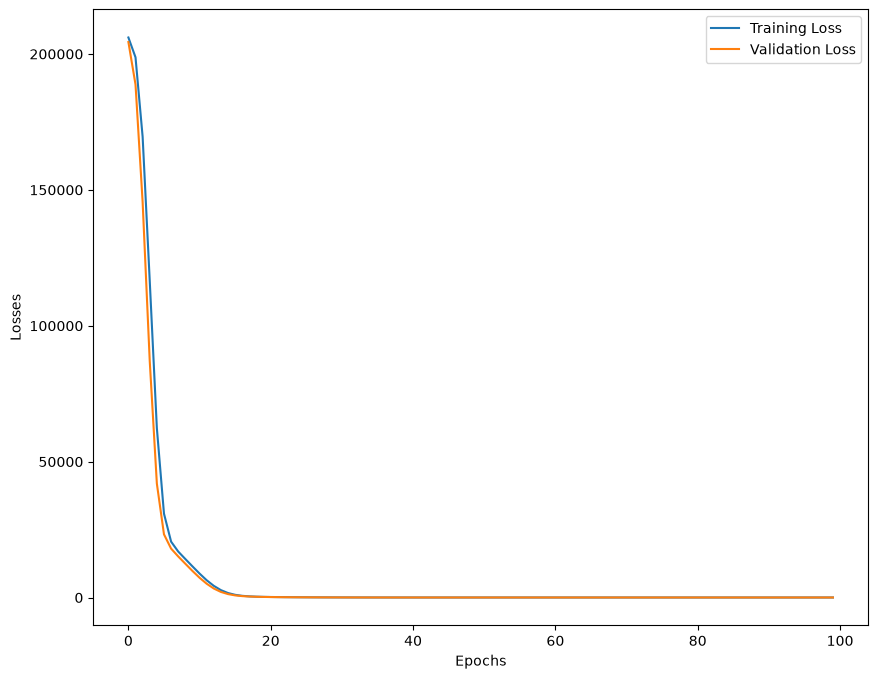

In [21]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss" : train_losses,
    "Validation Loss" : val_losses
})

plt.figure(figsize=(10,8))
plt.plot(loss_df["Training Loss"],label="Training Loss")
plt.plot(loss_df["Validation Loss"],label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [22]:
#Loading the best model

model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [24]:
#Evaluate our Model

model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = criterion(train_preds,y_train_tensor)
    test_mse_loss = criterion(test_preds,y_test_tensor)
    
print("Training MSE : ",train_mse_loss.item())
print("Testing MSE : ",test_mse_loss.item())

Training MSE :  20.721487045288086
Testing MSE :  19.2393856048584


In [27]:
from sklearn.metrics import r2_score

print("R2 Score : ",r2_score(y_test,test_preds)*100)

R2 Score :  93.27633165464687


In [31]:
predicted_df = pd.DataFrame(test_preds.numpy(),columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values,columns=["Actual Values"])

pd.concat([predicted_df,actual_df],axis=1)

,Predicted Values,Actual Values
0,435.624908,433.27
1,437.198700,438.16
2,461.211914,458.42
3,475.976532,480.82
4,435.709015,441.41
...,...,...
1909,451.360260,456.70
1910,431.974792,438.04
1911,467.606781,467.80
1912,431.436523,437.14
